# Learn a model, then test a different geography

**Foundations · 25 minutes · actual fitted regression on invented data**

Machine learning can begin with a small, inspectable model. Here Python learns a line from six invented observations in a fictional western zone. We reserve all six observations in an eastern zone for evaluation. The zones are abstract grid groups; they are not actual places.

**Learning question:** Does a model that fits one group transfer to another?

Choose the held-out zone before fitting. All responses and predictor values are invented; their units are arbitrary. No model service, satellite imagery, health records, or additional package installation is used.

## Predict before running

The data deliberately contain both a relationship and a regional difference. A fitted line minimizes squared training residuals. A residual is observed minus predicted. Low training error alone does not establish good performance in a new region.

Write down which zone you expect to have larger errors and why.


In [1]:
from statistics import mean

# Original deterministic fixture: one predictor, two fictional spatial groups.
noise = [0, 1, -1, 1, -1, 0]
train = [{"site": f"W{i}", "zone": "West", "x": i, "y": 2*i+1+noise[i]}
         for i in range(6)]
east_offset = 8  # Editable regional assumption; compare with 1.
test = [{"site": f"E{i}", "zone": "East", "x": i+6, "y": 2*(i+6)+east_offset+noise[i]}
        for i in range(6)]
print("Training sites:", [r["site"] for r in train])
print("Held-out sites:", [r["site"] for r in test])
print("All values invented; x and y have arbitrary units.")


Training sites: ['W0', 'W1', 'W2', 'W3', 'W4', 'W5']
Held-out sites: ['E0', 'E1', 'E2', 'E3', 'E4', 'E5']
All values invented; x and y have arbitrary units.


## Fit using the western group only

The fitted slope is the sum of centered predictor–response products divided by the sum of squared centered predictors. The intercept puts the fitted line through the training means. The function rejects a predictor with no variation because this calculation cannot estimate its slope.

The eastern responses are not passed to the fit function. The assertion checks the calculation on an exact line; it does not validate an application.


In [2]:
def fit_line(rows):
    if len(rows) < 2:
        raise ValueError("Use at least two training observations.")
    xbar = mean(r["x"] for r in rows)
    ybar = mean(r["y"] for r in rows)
    denominator = sum((r["x"]-xbar)**2 for r in rows)
    if denominator == 0:
        raise ValueError("Training predictor must vary.")
    slope = sum((r["x"]-xbar)*(r["y"]-ybar) for r in rows)/denominator
    return ybar-slope*xbar, slope

assert fit_line([{"x": 0, "y": 1}, {"x": 1, "y": 3}, {"x": 2, "y": 5}]) == (1.0, 2.0)
intercept, slope = fit_line(train)
def predict(row):
    return intercept+slope*row["x"]

print(f"Learned line: y_hat = {intercept:.4f} + {slope:.4f} * x")


Learned line: y_hat = 1.2857 + 1.8857 * x


## Evaluate without refitting

Compare mean absolute error (MAE) on training and held-out sites. MAE has the response's units. Also compare a baseline that always predicts the training mean.

The test group differs in both predictor range and an assumed regional offset. This example exposes a combined extrapolation and distribution-shift problem; it does not isolate spatial dependence or estimate real geographic accuracy.


In [3]:
def mae(rows, predictor):
    return mean(abs(r["y"]-predictor(r)) for r in rows)

baseline = mean(r["y"] for r in train)
metrics = {
    "West training MAE": mae(train, predict),
    "East held-out MAE": mae(test, predict),
    "East constant-baseline MAE": mae(test, lambda r: baseline),
}
for label, value in metrics.items():
    print(f"{label}: {value:.3f} response units")
for row in train+test:
    print(row["site"], "observed", row["y"], "predicted",
          round(predict(row), 3), "residual", round(row["y"]-predict(row), 3))


West training MAE: 0.724 response units
East held-out MAE: 7.686 response units
East constant-baseline MAE: 19.000 response units
W0 observed 1 predicted 1.286 residual -0.286
W1 observed 4 predicted 3.171 residual 0.829
W2 observed 4 predicted 5.057 residual -1.057
W3 observed 8 predicted 6.943 residual 1.057
W4 observed 8 predicted 8.829 residual -0.829
W5 observed 11 predicted 10.714 residual 0.286
E0 observed 20 predicted 12.6 residual 7.4
E1 observed 23 predicted 14.486 residual 8.514
E2 observed 23 predicted 16.371 residual 6.629
E3 observed 27 predicted 18.257 residual 8.743
E4 observed 27 predicted 20.143 residual 6.857
E5 observed 30 predicted 22.029 residual 7.971


## Read the visual evidence

The scatterplot shows observations and the learned line. The residual grid retains each site's group and signed error. These grid positions are a schematic arrangement of the two groups, not geographic coordinates. The printed values above are the text alternative.

Teal circles are western training observations; orange squares are eastern held-out observations. In the default fixture, error in the eastern zone remains systematic even though the model improves on the simple baseline.


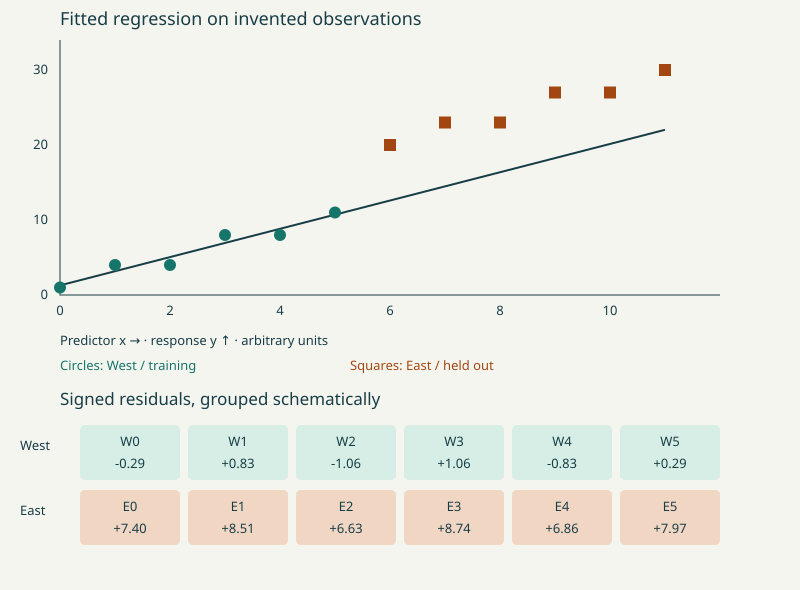

In [4]:
from IPython.display import SVG, display
from html import escape

sx = lambda x: 60+x*55
sy = lambda y: 295-y*7.5
parts = ['<rect width="800" height="590" fill="#f5f5ef"/>',
         '<path d="M60 40V295H720" fill="none" stroke="#173d46"/>',
         '<text x="60" y="25" font-family="sans-serif" font-size="18">Fitted regression on invented observations</text>']
for x in range(0, 12, 2):
    parts.append(f'<text x="{sx(x)}" y="315" text-anchor="middle">{x}</text>')
for y in [0, 10, 20, 30]:
    parts.append(f'<text x="48" y="{sy(y)+4}" text-anchor="end">{y}</text>')
parts.append(f'<path d="M{sx(0)} {sy(intercept)}L{sx(11)} {sy(intercept+slope*11)}" stroke="#173d46" stroke-width="2" fill="none"/>')
for r in train:
    parts.append(f'<circle cx="{sx(r["x"])}" cy="{sy(r["y"])}" r="6" fill="#16756b"/>')
for r in test:
    parts.append(f'<rect x="{sx(r["x"])-6}" y="{sy(r["y"])-6}" width="12" height="12" fill="#a34712"/>')
parts += ['<text x="60" y="345">Predictor x → · response y ↑ · arbitrary units</text>',
          '<text x="60" y="370" fill="#16756b">Circles: West / training</text>',
          '<text x="350" y="370" fill="#a34712">Squares: East / held out</text>',
          '<text x="60" y="405" font-size="17">Signed residuals, grouped schematically</text>']
for j, group in enumerate([train, test]):
    parts.append(f'<text x="20" y="{450+j*65}">{group[0]["zone"]}</text>')
    for i, r in enumerate(group):
        x, y = 80+i*108, 425+j*65
        residual = r["y"]-predict(r)
        fill = "#d6eee5" if j == 0 else "#f2d6c4"
        parts.append(f'<rect x="{x}" y="{y}" width="100" height="55" rx="5" fill="{fill}"/>'
                     f'<text x="{x+50}" y="{y+21}" text-anchor="middle">{escape(r["site"])}</text>'
                     f'<text x="{x+50}" y="{y+43}" text-anchor="middle">{residual:+.2f}</text>')
display(SVG('<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 800 590" role="img" aria-label="Fitted model and grouped residuals on synthetic data"><title>Train here, test elsewhere</title><desc>A line fitted to western training observations is compared with eastern held-out observations. Each signed residual is printed in a labeled group grid.</desc><g font-family="sans-serif" font-size="13" fill="#173d46">'+"".join(parts)+'</g></svg>'))


## Interpret, then change one thing

The line was learned from data. It is a simple supervised-learning example, using ordinary least squares rather than a large model. It captures a training relationship and misses the deliberately added eastern offset.

Make a **new** experiment by setting `east_offset` from 8 to 1. Predict the outcome, restart the kernel, and rerun. Keep the original result as a separate experiment record. Tuning repeatedly against the same test responses would turn them into development data; use a new held-out group for a final assessment.

Try adding one extreme training observation. Least squares can be sensitive to outliers. A larger model does not automatically solve missing geography, biased sampling, poor measurements, or unclear decision goals.

For a real project, choose evaluation groups to reflect the intended use, document data provenance and units, and consider spatial dependence, missingness, uncertainty and community review. This fixture is too small and artificial to establish any real-world model performance.

Continue with [the GeoAI companion](../projects/geolibre-geoai/index.ipynb), [spatial thinking](spatial-thinking.ipynb), and [evidence and human agency](evidence-ai.ipynb).

## Sources and attribution

- NIST/SEMATECH. [e-Handbook of Statistical Methods: Linear Least Squares Regression](https://www.itl.nist.gov/div898/handbook/pmd/section1/pmd141.htm). Method background and limitations; original explanation and implementation here.
- Scikit-learn developers. [Cross-validation: evaluating estimator performance](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-iterators-for-grouped-data). Background on held-out evaluation and groups. Scikit-learn is referenced, not installed by this notebook.
- Original synthetic fixture and SVG: James L. Tobias and contributors (2026), CC BY 4.0. Original code: MIT. Sources checked 2026-11-01.

[Central references](../references.ipynb) · [Contribute](../contributor-guide.ipynb)

Download your notebook to retain changes. Files and edits in JupyterLite remain local to the browser/profile until exported.
